In [1]:
import os, csv
import numpy as np

R = os.path.expanduser("~/waerme/results/")
f = R + "e14_ghost_2026-11-09.csv"
with open(f) as fh:
    zeilen = list(csv.reader(fh))
print("Kopfzeile:", zeilen[0])
print("Erste Datenzeile:", zeilen[1])
print("Zeilen gesamt:", len(zeilen), "(erwartet 181)")

Kopfzeile: ['datum', 'P', 'N', 'schritte', 'zeit_s', 'komm_max_s', 'summe', 'g']
Erste Datenzeile: ['2026-11-09', '48', '256', '200', '0.053156', '0.051452', '1.6454456882e+05', '1']
Zeilen gesamt: 181 (erwartet 181)


In [2]:
import math
from collections import defaultdict

def ki(werte):
    s = sorted(werte); n = len(s)
    lo = max(1, math.floor((n - 1.96*math.sqrt(n)) / 2))
    hi = min(n, math.ceil(1 + (n + 1.96*math.sqrt(n)) / 2))
    return s[lo-1], s[hi-1]

gr = defaultdict(list)
for z in zeilen[1:]:
    d = dict(zip(zeilen[0], z))
    gr[(int(d["N"]), int(d["g"]))].append((float(d["zeit_s"]), float(d["komm_max_s"])))

e14 = {}
print("N     g   n   Median[s]  95%-KI [s]          Komm%  Faktor")
for (N, g) in sorted(gr):
    zeit = [a for a, b in gr[(N, g)]]
    komm = [b for a, b in gr[(N, g)]]
    med = float(np.median(zeit)); lo, hi = ki(zeit)
    kp = 100 * float(np.median(komm)) / med
    e14[(N, g)] = (med, lo, hi, kp)
    fak = e14[(N, 1)][0] / med
    print(f"{N:<5} {g}  {len(zeit):>3}  {med:.4f}   {lo:.4f}-{hi:.4f}   {kp:>4.0f}   {fak:.2f}")

N     g   n   Median[s]  95%-KI [s]          Komm%  Faktor
256   1   15  0.0526   0.0515-0.0537     97   1.00
256   2   15  0.0331   0.0325-0.0335     95   1.59
256   4   15  0.0205   0.0203-0.0224     94   2.57
512   1   15  0.0668   0.0649-0.0707     95   1.00
512   2   15  0.0409   0.0398-0.0427     94   1.63
512   4   15  0.0308   0.0295-0.0338     91   2.17
1024  1   15  0.0835   0.0816-0.0894     91   1.00
1024  2   15  0.0633   0.0608-0.0706     87   1.32
1024  4   15  0.0529   0.0510-0.0634     84   1.58
2048  1   15  0.1368   0.1326-0.1427     79   1.00
2048  2   15  0.1178   0.1133-0.1292     75   1.16
2048  4   15  0.1355   0.1336-0.1391     78   1.01


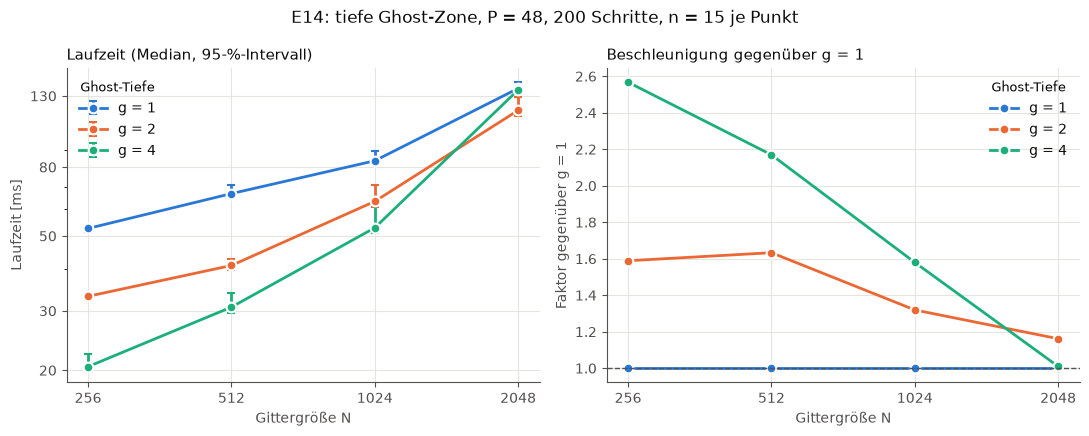

gespeichert: /home/itmvs/waerme/results/e14_ghost_2026-11-09.png 120561 Bytes


In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, NullFormatter

Ns = [256, 512, 1024, 2048]
farbe = {1: "#2a78d6", 2: "#eb6834", 4: "#1baf7a"}   # Blau, Orange, Aqua
tinte, grau, raster = "#0b0b0b", "#52514e", "#e5e4df"

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4))
for g in (1, 2, 4):
    med = np.array([e14[(N, g)][0] for N in Ns]) * 1000
    lo  = np.array([e14[(N, g)][1] for N in Ns]) * 1000
    hi  = np.array([e14[(N, g)][2] for N in Ns]) * 1000
    fak = np.array([e14[(N, 1)][0] / e14[(N, g)][0] for N in Ns])
    a1.errorbar(Ns, med, yerr=[med - lo, hi - med], fmt="-o", color=farbe[g],
                lw=2, ms=7, mec="white", mew=1.5, capsize=3, label=f"g = {g}")
    a2.plot(Ns, fak, "-o", color=farbe[g], lw=2, ms=7, mec="white", mew=1.5, label=f"g = {g}")

a2.axhline(1, color=grau, lw=1, ls="--")
a1.set_yscale("log")
for a in (a1, a2):
    a.set_xscale("log", base=2)
    a.set_xticks(Ns); a.set_xticklabels([str(n) for n in Ns])
    a.xaxis.set_minor_formatter(NullFormatter())
    a.set_xlabel("Gittergröße N", color=grau)
    a.grid(True, color=raster, lw=0.8); a.set_axisbelow(True)
    for s in ("top", "right"): a.spines[s].set_visible(False)
    for s in ("left", "bottom"): a.spines[s].set_color(grau)
    a.tick_params(colors=grau)
    a.legend(frameon=False, labelcolor=tinte, title="Ghost-Tiefe", title_fontsize=9)
a1.yaxis.set_major_formatter(ScalarFormatter()); a1.yaxis.set_minor_formatter(NullFormatter())
a1.set_yticks([20, 30, 50, 80, 130])
a1.set_ylabel("Laufzeit [ms]", color=grau)
a2.set_ylabel("Faktor gegenüber g = 1", color=grau)
a1.set_title("Laufzeit (Median, 95-%-Intervall)", color=tinte, fontsize=11, loc="left")
a2.set_title("Beschleunigung gegenüber g = 1", color=tinte, fontsize=11, loc="left")
fig.suptitle("E14: tiefe Ghost-Zone, P = 48, 200 Schritte, n = 15 je Punkt", color=tinte, fontsize=12)
fig.tight_layout()
datei = R + "e14_ghost_2026-11-09.png"
fig.savefig(datei, dpi=150, facecolor="white")
plt.show()
print("gespeichert:", datei, os.path.getsize(datei), "Bytes")

In [4]:
f15 = R + "e15_allreduce_2026-11-09.csv"
with open(f15) as fh:
    z15 = list(csv.reader(fh))
print("Kopfzeile:", z15[0])
print("Erste Datenzeile:", z15[1])
print("Zeilen gesamt:", len(z15), "(erwartet 481)")

Kopfzeile: ['datum', 'map', 'P', 'm', 'reps', 'zeit_s', 'ergebnis']
Erste Datenzeile: ['2026-11-09', 'slot', '1', '1', '1000', '0.000002880', '1.0']
Zeilen gesamt: 481 (erwartet 481)


In [5]:
g15 = defaultdict(list)
falsch = 0
for z in z15[1:]:
    d = dict(zip(z15[0], z))
    g15[(int(d["m"]), int(d["P"]), d["map"])].append(float(d["zeit_s"]) * 1e6)
    if float(d["ergebnis"]) != float(d["P"]):
        falsch += 1

e15 = {}
print("m        P   map        n   Median[us]   95%-KI [us]")
for key in sorted(g15):
    w = g15[key]
    med = float(np.median(w)); lo, hi = ki(w)
    e15[key] = (med, lo, hi, len(w))
    m, P, mp = key
    print(f"{m:<8} {P:<3} {mp:<10} {len(w):>2}   {med:>10.1f}   {lo:.1f}-{hi:.1f}")
print("Gruppen:", len(g15), "(erwartet 32) | falsche Ergebnisse:", falsch, "(erwartet 0)")

m        P   map        n   Median[us]   95%-KI [us]
1        1   slot       15          3.0   2.9-3.1
1        2   slot       15          5.3   5.2-5.4
1        4   slot       15          4.0   3.9-4.5
1        8   ppr:2:node 15        137.8   134.6-142.1
1        12  ppr:3:node 15        227.2   224.0-230.9
1        12  slot       15          9.6   5.9-10.2
1        24  ppr:6:node 15        242.3   236.6-247.5
1        48  ppr:12:node 15        271.0   265.0-273.4
1000     1   slot       15          3.4   3.3-3.5
1000     2   slot       15         10.3   10.2-10.5
1000     4   slot       15         17.6   17.3-18.3
1000     8   ppr:2:node 15        522.7   503.2-529.5
1000     12  ppr:3:node 15        673.2   654.6-678.2
1000     12  slot       15         49.1   41.1-56.2
1000     24  ppr:6:node 15        863.3   849.4-877.6
1000     48  ppr:12:node 15        822.9   803.6-828.1
100000   1   slot       15         58.8   58.3-59.2
100000   2   slot       15        226.5   223.5-228.2


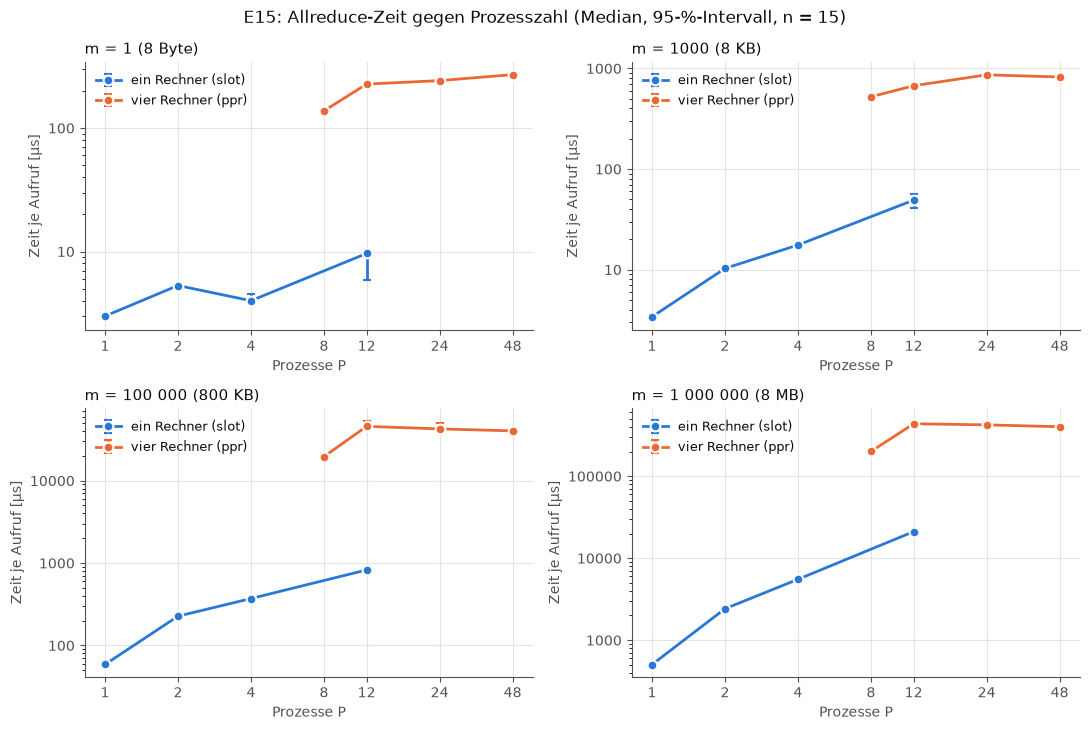

gespeichert: /home/itmvs/waerme/results/e15_allreduce_2026-11-09.png 146821 Bytes


In [6]:
titel = {1: "m = 1 (8 Byte)", 1000: "m = 1000 (8 KB)",
         100000: "m = 100 000 (800 KB)", 1000000: "m = 1 000 000 (8 MB)"}
slot_P = [1, 2, 4, 12]
ppr_P = {8: "ppr:2:node", 12: "ppr:3:node", 24: "ppr:6:node", 48: "ppr:12:node"}
blau, orange = "#2a78d6", "#eb6834"

fig, achsen = plt.subplots(2, 2, figsize=(11, 7.4))
for a, m in zip(achsen.ravel(), (1, 1000, 100000, 1000000)):
    for P_liste, farbe, name in ((slot_P, blau, "ein Rechner (slot)"),
                                 (list(ppr_P), orange, "vier Rechner (ppr)")):
        keys = [(m, P, "slot" if farbe == blau else ppr_P[P]) for P in P_liste]
        med = np.array([e15[k][0] for k in keys])
        lo  = np.array([e15[k][1] for k in keys])
        hi  = np.array([e15[k][2] for k in keys])
        a.errorbar(P_liste, med, yerr=[med - lo, hi - med], fmt="-o", color=farbe,
                   lw=2, ms=7, mec="white", mew=1.5, capsize=3, label=name)
    a.set_xscale("log", base=2); a.set_yscale("log")
    a.set_xticks([1, 2, 4, 8, 12, 24, 48]); a.set_xticklabels(["1", "2", "4", "8", "12", "24", "48"])
    a.xaxis.set_minor_formatter(NullFormatter()); a.yaxis.set_major_formatter(ScalarFormatter())
    a.yaxis.set_minor_formatter(NullFormatter())
    a.set_title(titel[m], color=tinte, fontsize=11, loc="left")
    a.set_xlabel("Prozesse P", color=grau); a.set_ylabel("Zeit je Aufruf [µs]", color=grau)
    a.grid(True, color=raster, lw=0.8); a.set_axisbelow(True)
    for s in ("top", "right"): a.spines[s].set_visible(False)
    for s in ("left", "bottom"): a.spines[s].set_color(grau)
    a.tick_params(colors=grau)
    a.legend(frameon=False, labelcolor=tinte, loc="upper left", fontsize=9)
fig.suptitle("E15: Allreduce-Zeit gegen Prozesszahl (Median, 95-%-Intervall, n = 15)", color=tinte, fontsize=12)
fig.tight_layout()
datei = R + "e15_allreduce_2026-11-09.png"
fig.savefig(datei, dpi=150, facecolor="white")
plt.show()
print("gespeichert:", datei, os.path.getsize(datei), "Bytes")

In [7]:
f16 = R + "e16b_ueberbelegung_2026-11-09.csv"
with open(f16) as fh:
    z16 = list(csv.reader(fh))
print("Kopfzeile:", z16[0])
print("Erste Datenzeile:", z16[1])
print("Zeilen gesamt:", len(z16), "(erwartet 61)")

Kopfzeile: ['datum', 'P', 'N', 'schritte', 'zeit_s', 'komm_max_s', 'summe', 'g']
Erste Datenzeile: ['2026-11-09', '48', '2048', '200', '0.154011', '0.125147', '1.3566003078e+06', '1']
Zeilen gesamt: 61 (erwartet 61)


In [8]:
g16 = defaultdict(list)
summen = defaultdict(set)
for z in z16[1:]:
    d = dict(zip(z16[0], z))
    g16[int(d["P"])].append((float(d["zeit_s"]), float(d["komm_max_s"])))
    summen[int(d["P"])].add(d["summe"])

e16 = {}
print("P    je Rechner  n   Median[s]  95%-KI [s]        Min-Max [s]       Komm%  Faktor  Summen")
for P in sorted(g16):
    zeit = [a for a, b in g16[P]]; komm = [b for a, b in g16[P]]
    med = float(np.median(zeit)); lo, hi = ki(zeit)
    kp = 100 * float(np.median(komm)) / med
    e16[P] = (med, lo, hi, min(zeit), max(zeit), kp)
    fak = e16[48][0] / e16[48][0] if P == 48 else med / e16[48][0]
    print(f"{P:<4} {P//4:<10} {len(zeit):>2}  {med:.4f}    {lo:.4f}-{hi:.4f}   {min(zeit):.4f}-{max(zeit):.4f}   {kp:>4.0f}   {fak:>5.2f}   {len(summen[P])}")

P    je Rechner  n   Median[s]  95%-KI [s]        Min-Max [s]       Komm%  Faktor  Summen
48   12         15  0.1489    0.1342-0.1593   0.1335-0.4515     81    1.00   1
96   24         15  0.1418    0.1369-0.1511   0.1365-0.1877     84    0.95   1
144  36         15  1.4193    1.3114-1.5443   1.2673-1.8327     99    9.53   1
192  48         15  2.1035    1.9965-2.1949   1.8882-2.3453     99   14.12   1


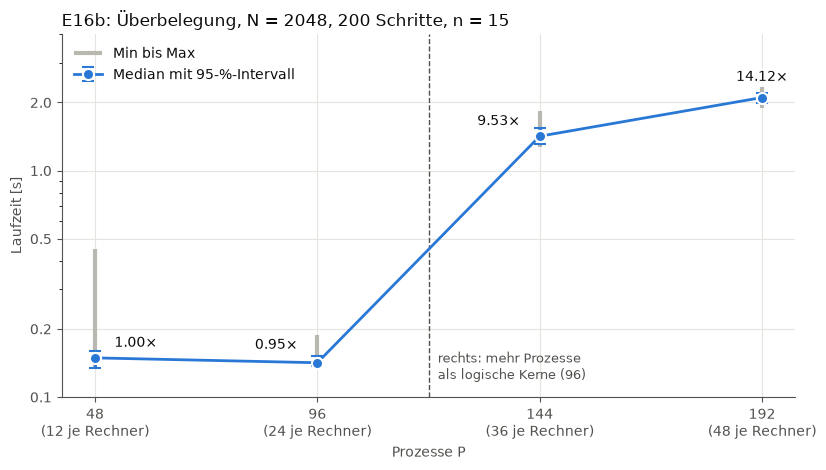

gespeichert: /home/itmvs/waerme/results/e16b_ueberbelegung_2026-11-09.png 77826 Bytes


In [10]:
Ps = [48, 96, 144, 192]
med = np.array([e16[P][0] for P in Ps]); lo = np.array([e16[P][1] for P in Ps])
hi = np.array([e16[P][2] for P in Ps]); mn = np.array([e16[P][3] for P in Ps])
mx = np.array([e16[P][4] for P in Ps])
blau, hell = "#2a78d6", "#b8b7b0"
versatz = {48: (14, 8, "left"), 96: (-14, 10, "right"), 144: (-14, 8, "right"), 192: (0, 12, "center")}

fig, a = plt.subplots(figsize=(8.4, 4.8))
a.vlines(Ps, mn, mx, color=hell, lw=3, label="Min bis Max", zorder=1)
a.errorbar(Ps, med, yerr=[med - lo, hi - med], fmt="-o", color=blau, lw=2, ms=8,
           mec="white", mew=1.5, capsize=4, label="Median mit 95-%-Intervall", zorder=3)
a.axvline(120, color=grau, lw=1, ls="--")
a.text(122, 0.115, "rechts: mehr Prozesse\nals logische Kerne (96)", color=grau, fontsize=9, va="bottom")
for P, m in zip(Ps, med):
    dx, dy, ha = versatz[P]
    a.annotate(f"{m / med[0]:.2f}×", (P, m), textcoords="offset points", xytext=(dx, dy),
               ha=ha, color=tinte, fontsize=10, zorder=5,
               bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))
a.set_yscale("log"); a.set_ylim(0.1, 4)
a.set_xticks(Ps); a.set_xticklabels([f"{P}\n({P//4} je Rechner)" for P in Ps])
a.set_yticks([0.1, 0.2, 0.5, 1, 2]); a.yaxis.set_major_formatter(ScalarFormatter())
a.yaxis.set_minor_formatter(NullFormatter())
a.set_xlabel("Prozesse P", color=grau); a.set_ylabel("Laufzeit [s]", color=grau)
a.set_title("E16b: Überbelegung, N = 2048, 200 Schritte, n = 15", color=tinte, fontsize=12, loc="left")
a.grid(True, color=raster, lw=0.8); a.set_axisbelow(True)
for s in ("top", "right"): a.spines[s].set_visible(False)
for s in ("left", "bottom"): a.spines[s].set_color(grau)
a.tick_params(colors=grau); a.legend(frameon=False, labelcolor=tinte, loc="upper left")
fig.tight_layout()
datei = R + "e16b_ueberbelegung_2026-11-09.png"
fig.savefig(datei, dpi=150, facecolor="white")
plt.show()
print("gespeichert:", datei, os.path.getsize(datei), "Bytes")

In [11]:
f6 = R + "e6_hybrid_2026-11-09.csv"
z6 = list(csv.reader(open(f6)))
print("Datei:", f6)
print("Kopfzeile:", ",".join(z6[0]))
print("Zeilen:", len(z6), "(erwartet 151)")
print("Beispiel:", z6[1])

Datei: /home/itmvs/waerme/results/e6_hybrid_2026-11-09.csv
Kopfzeile: datum,P,N,schritte,zeit_s,komm_max_s,summe,T
Zeilen: 151 (erwartet 151)
Beispiel: ['2026-11-09', '48', '2048', '200', '0.139196', '0.109560', '1.3566003078e+06', '1']


In [13]:
import math
g6 = {}
for r in z6[1:]:
    g6.setdefault((int(r[2]), int(r[1]), int(r[7])), []).append((float(r[4]), float(r[5]), r[6]))
e6 = {}
print(f"{'N':>5} {'P×T':>6} {'n':>3} {'Median':>8} {'CI_lo':>8} {'CI_hi':>8} {'Min':>8} {'Max':>8} {'Komm%':>6} {'Summen':>6}")
for (N, P, T) in sorted(g6, key=lambda k: (k[0], -k[1])):
    w = g6[(N, P, T)]
    z = sorted(x[0] for x in w); n = len(z)
    lo = z[math.floor((n - 1.96 * math.sqrt(n)) / 2) - 1]
    hi = z[math.ceil(1 + (n + 1.96 * math.sqrt(n)) / 2) - 1]
    med = float(np.median(z))
    kp = 100 * float(np.median([x[1] for x in w])) / med
    ns = len(set(x[2] for x in w))
    e6[(N, P, T)] = (med, lo, hi, z[0], z[-1], kp, n)
    print(f"{N:>5} {str(P)+'×'+str(T):>6} {n:>3} {med:8.4f} {lo:8.4f} {hi:8.4f} {z[0]:8.4f} {z[-1]:8.4f} {kp:6.1f} {ns:>6}")
print("Gruppen:", len(e6), "(erwartet 10)")

    N    P×T   n   Median    CI_lo    CI_hi      Min      Max  Komm% Summen
 2048   48×1  15   0.1431   0.1380   0.1550   0.1362   0.1601   79.1      1
 2048   24×2  15   0.1505   0.1377   0.1555   0.1339   0.1594   79.6      1
 2048   12×4  15   0.1345   0.1326   0.1430   0.1320   0.1563   77.0      1
 2048    8×6  15   0.1462   0.1365   0.1550   0.1336   0.1700   78.5      1
 2048   4×12  15   0.1598   0.1434   0.1687   0.1414   0.1706   75.1      1
 4096   48×1  15   0.4577   0.4565   0.4591   0.4559   0.4624   50.5      1
 4096   24×2  15   0.4689   0.4672   0.4768   0.4594   0.4872   54.3      1
 4096   12×4  15   0.4872   0.4804   0.4913   0.4783   0.5018   62.2      1
 4096    8×6  15   0.4959   0.4866   0.5016   0.4846   0.5055   52.3      1
 4096   4×12  15   0.6440   0.6279   0.6546   0.6271   0.6730   31.4      1
Gruppen: 10 (erwartet 10)


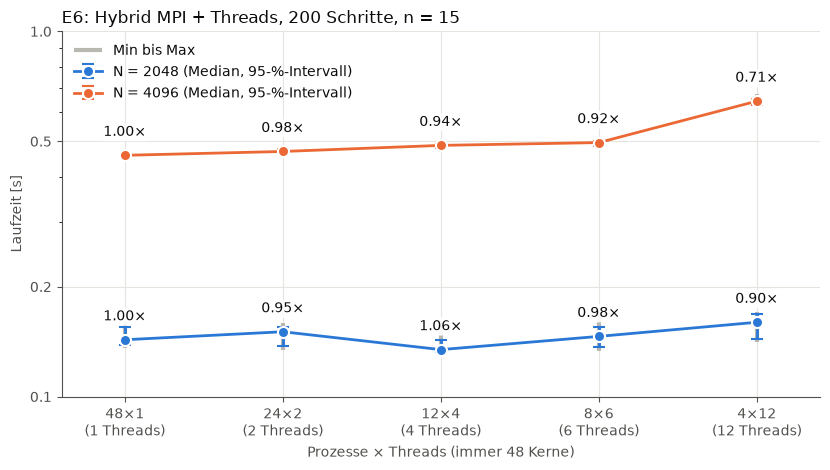

gespeichert: /home/itmvs/waerme/results/e6_hybrid_2026-11-09.png 85923 Bytes


In [14]:
konf = [(48, 1), (24, 2), (12, 4), (8, 6), (4, 12)]
xs = np.arange(len(konf))
blau, orange, hell = "#2a78d6", "#eb6834", "#b8b7b0"

fig, a = plt.subplots(figsize=(8.4, 4.8))
for N, farbe in ((2048, blau), (4096, orange)):
    med = np.array([e6[(N, P, T)][0] for P, T in konf]); lo = np.array([e6[(N, P, T)][1] for P, T in konf])
    hi = np.array([e6[(N, P, T)][2] for P, T in konf]); mn = np.array([e6[(N, P, T)][3] for P, T in konf])
    mx = np.array([e6[(N, P, T)][4] for P, T in konf])
    a.vlines(xs, mn, mx, color=hell, lw=3, zorder=1, label="Min bis Max" if N == 2048 else None)
    a.errorbar(xs, med, yerr=[med - lo, hi - med], fmt="-o", color=farbe, lw=2, ms=8, mec="white", mew=1.5,
               capsize=4, zorder=3, label=f"N = {N} (Median, 95-%-Intervall)")
    for x, m in zip(xs, med):
        a.annotate(f"{med[0] / m:.2f}×", (x, m), textcoords="offset points", xytext=(0, 14), ha="center",
                   color=tinte, fontsize=10, zorder=5,
                   bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))
a.set_yscale("log"); a.set_ylim(0.1, 1)
a.set_xlim(-0.4, len(konf) - 0.6)
a.set_xticks(xs); a.set_xticklabels([f"{P}×{T}\n({T} Threads)" for P, T in konf])
a.set_yticks([0.1, 0.2, 0.5, 1]); a.yaxis.set_major_formatter(ScalarFormatter())
a.yaxis.set_minor_formatter(NullFormatter())
a.set_xlabel("Prozesse × Threads (immer 48 Kerne)", color=grau); a.set_ylabel("Laufzeit [s]", color=grau)
a.set_title("E6: Hybrid MPI + Threads, 200 Schritte, n = 15", color=tinte, fontsize=12, loc="left")
a.grid(True, color=raster, lw=0.8); a.set_axisbelow(True)
for s in ("top", "right"): a.spines[s].set_visible(False)
for s in ("left", "bottom"): a.spines[s].set_color(grau)
a.tick_params(colors=grau); a.legend(frameon=False, labelcolor=tinte, loc="upper left")
fig.tight_layout()
datei = R + "e6_hybrid_2026-11-09.png"
fig.savefig(datei, dpi=150, facecolor="white")
plt.show()
print("gespeichert:", datei, os.path.getsize(datei), "Bytes")

In [15]:
f18 = R + "e18_thp_aus_2026-11-09.csv"
z18 = list(csv.reader(open(f18)))
print("Datei:", f18)
print("Kopfzeile:", ",".join(z18[0]))
print("Zeilen:", len(z18), "(erwartet 241)")
print("Beispiel:", z18[1])
kopf = z18[0]
for s in ("thp", "P", "N", "schritte"):
    i = kopf.index(s)
    print(s, "→", sorted(set(r[i] for r in z18[1:]), key=float))

Datei: /home/itmvs/waerme/results/e18_thp_aus_2026-11-09.csv
Kopfzeile: datum,thp,P,N,schritte,zeit_s,komm_max_s,summe
Zeilen: 241 (erwartet 241)
Beispiel: ['2026-11-09', '1', '1', '2048', '200', '1.337276', '0.003886', '1.3566003078e+06']
thp → ['0', '1']
P → ['1', '2', '4']
N → ['2048', '4096']
schritte → ['200']


In [16]:
import math
from math import comb
g18 = {}
for r in z18[1:]:
    g18.setdefault((int(r[3]), int(r[2]), int(r[1])), []).append((float(r[5]), float(r[6]), r[7]))
e18 = {}
print(f"{'N':>5} {'P':>2} {'Feld':>6} {'thp':>3} {'n':>3} {'Median':>8} {'CI_lo':>8} {'CI_hi':>8} {'Min':>8} {'Max':>8} {'langsam':>8} {'Summen':>6} {'thp1/thp0':>9}")
for (N, P, thp) in sorted(g18):
    w = g18[(N, P, thp)]
    z = sorted(x[0] for x in w); n = len(z)
    lo = z[math.floor((n - 1.96 * math.sqrt(n)) / 2) - 1]
    hi = z[math.ceil(1 + (n + 1.96 * math.sqrt(n)) / 2) - 1]
    med = float(np.median(z))
    ref = float(np.median([x[0] for x in g18[(N, P, 0)]]))
    langsam = sum(1 for x in z if x > 1.15 * ref)
    zeilen_max = N // P + (0 if P == 1 else (1 if P == 2 else 2))
    feld = zeilen_max * N * 8 / 2**20
    ns = len(set(x[2] for x in w))
    verh = med / ref
    e18[(N, P, thp)] = (med, lo, hi, z[0], z[-1], langsam, n, verh)
    print(f"{N:>5} {P:>2} {feld:6.1f} {thp:>3} {n:>3} {med:8.4f} {lo:8.4f} {hi:8.4f} {z[0]:8.4f} {z[-1]:8.4f} {langsam:>5}/{n:<2} {ns:>6} {verh:9.2f}")
print("Gruppen:", len(e18), "(erwartet 12)")

def fisher(a, b, n=20):
    K = a + b
    p = lambda x: comb(n, x) * comb(n, K - x) / comb(2 * n, K)
    po = p(a)
    return sum(p(x) for x in range(max(0, K - n), min(n, K) + 1) if p(x) <= po * (1 + 1e-9))
print()
for (N, P) in sorted({(k[0], k[1]) for k in e18}):
    a = e18[(N, P, 1)][5]; b = e18[(N, P, 0)][5]
    print(f"Fisher N={N} P={P}: thp=1 langsam {a}/20 gegen thp=0 {b}/20, p = {fisher(a, b):.2g}")

    N  P   Feld thp   n   Median    CI_lo    CI_hi      Min      Max  langsam Summen thp1/thp0
 2048  1   32.0   0  20   1.3395   1.3378   1.3422   1.3365   1.3508     0/20      1      1.00
 2048  1   32.0   1  20   2.2093   2.2016   2.2158   1.3313   2.2204    16/20      1      1.65
 2048  2   16.0   0  20   0.7202   0.7184   0.7220   0.7169   0.7277     0/20      1      1.00
 2048  2   16.0   1  20   0.7228   0.7151   0.7353   0.7124   0.7494     0/20      1      1.00
 2048  4    8.0   0  20   0.4917   0.4905   0.4932   0.4890   0.4969     0/20      1      1.00
 2048  4    8.0   1  20   0.4997   0.4941   0.5044   0.4860   0.6534     1/20      1      1.02
 4096  1  128.0   0  20   5.3347   5.3257   5.3456   5.3114   5.3569     0/20      1      1.00
 4096  1  128.0   1  20   5.1913   5.1865   5.1953   5.1836   5.2214     0/20      1      0.97
 4096  2   64.0   0  20   2.8362   2.8319   2.8451   2.8272   2.8463     0/20      1      1.00
 4096  2   64.0   1  20   2.8090   2.7993   2.8128

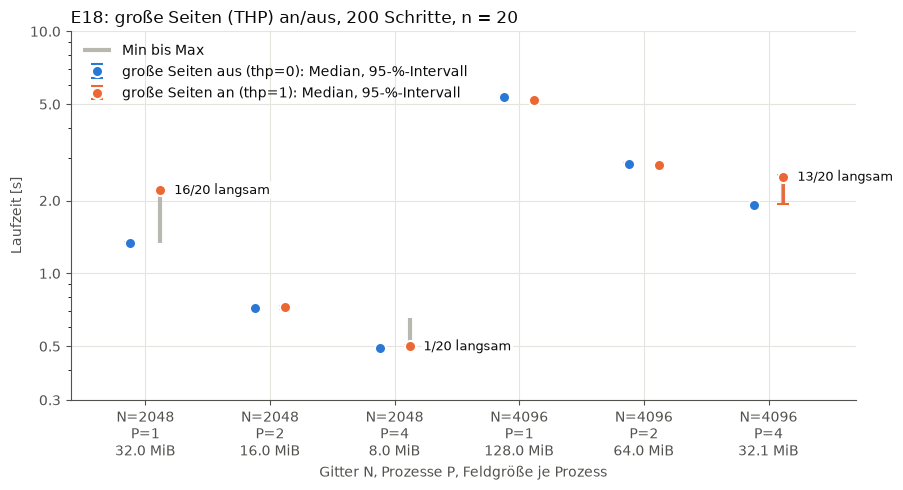

gespeichert: /home/itmvs/waerme/results/e18_thp_aus_2026-11-09.png 92414 Bytes


In [17]:
konf = [(2048, 1), (2048, 2), (2048, 4), (4096, 1), (4096, 2), (4096, 4)]
xs = np.arange(len(konf))
blau, orange, hell = "#2a78d6", "#eb6834", "#b8b7b0"
fig, a = plt.subplots(figsize=(9.2, 5.0))
for thp, farbe, dx, name in ((0, blau, -0.12, "große Seiten aus (thp=0)"), (1, orange, 0.12, "große Seiten an (thp=1)")):
    d = [e18[(N, P, thp)] for N, P in konf]
    med = np.array([x[0] for x in d]); lo = np.array([x[1] for x in d]); hi = np.array([x[2] for x in d])
    mn = np.array([x[3] for x in d]); mx = np.array([x[4] for x in d])
    a.vlines(xs + dx, mn, mx, color=hell, lw=3, zorder=1, label="Min bis Max" if thp == 0 else None)
    a.errorbar(xs + dx, med, yerr=[med - lo, hi - med], fmt="o", color=farbe, ms=8, mec="white", mew=1.5,
               capsize=4, lw=2, zorder=3, label=f"{name}: Median, 95-%-Intervall")
    if thp == 1:
        for x, dd in zip(xs, d):
            if dd[5] > 0:
                a.annotate(f"{dd[5]}/20 langsam", (x + dx, dd[0]), textcoords="offset points", xytext=(10, 0),
                           ha="left", va="center", color=tinte, fontsize=9, zorder=5,
                           bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.9))
a.set_yscale("log"); a.set_ylim(0.3, 10)
a.set_xlim(-0.6, len(konf) - 0.3)
def feld(N, P): return (N // P + (0 if P == 1 else (1 if P == 2 else 2))) * N * 8 / 2**20
a.set_xticks(xs); a.set_xticklabels([f"N={N}\nP={P}\n{feld(N, P):.1f} MiB" for N, P in konf])
a.set_yticks([0.3, 0.5, 1, 2, 5, 10]); a.yaxis.set_major_formatter(ScalarFormatter())
a.yaxis.set_minor_formatter(NullFormatter())
a.set_xlabel("Gitter N, Prozesse P, Feldgröße je Prozess", color=grau); a.set_ylabel("Laufzeit [s]", color=grau)
a.set_title("E18: große Seiten (THP) an/aus, 200 Schritte, n = 20", color=tinte, fontsize=12, loc="left")
a.grid(True, color=raster, lw=0.8); a.set_axisbelow(True)
for s in ("top", "right"): a.spines[s].set_visible(False)
for s in ("left", "bottom"): a.spines[s].set_color(grau)
a.tick_params(colors=grau); a.legend(frameon=False, labelcolor=tinte, loc="upper left")
fig.tight_layout()
datei = R + "e18_thp_aus_2026-11-09.png"
fig.savefig(datei, dpi=150, facecolor="white")
plt.show()
print("gespeichert:", datei, os.path.getsize(datei), "Bytes")

In [18]:
f13c = R + "e13c_kern_2026-11-09.csv"
z13c = list(csv.reader(open(f13c)))
kopf = z13c[0]
print("Datei:", f13c)
print("Kopfzeile:", ",".join(kopf))
print("Zeilen:", len(z13c), "(erwartet 161)")
print("Beispiel:", z13c[1])
for s in ("kern", "P", "N", "schritte"):
    i = kopf.index(s)
    print(s, "→", sorted(set(r[i] for r in z13c[1:]), key=float))
i = kopf.index("kern")
print("Läufe je kern:", {k: sum(1 for r in z13c[1:] if r[i] == k) for k in sorted(set(r[i] for r in z13c[1:]), key=float)})
print("verschiedene Summen:", len(set(r[kopf.index("summe")] for r in z13c[1:])))

Datei: /home/itmvs/waerme/results/e13c_kern_2026-11-09.csv
Kopfzeile: datum,kern,P,N,schritte,zeit_s,komm_max_s,summe
Zeilen: 161 (erwartet 161)
Beispiel: ['2026-11-09_11:38:06', '0', '1', '2048', '200', '2.220223', '0.003683', '1.3566003078e+06']
kern → ['0', '2', '12', '22']
P → ['1']
N → ['2048']
schritte → ['200']
Läufe je kern: {'0': 40, '2': 40, '12': 40, '22': 40}
verschiedene Summen: 1


In [19]:
import math
from math import comb
k13 = {}
for r in z13c[1:]:
    k13.setdefault(int(r[1]), []).append(float(r[5]))
alle = sorted(x for v in k13.values() for x in v)
ref = float(np.median(alle[:16])); schwelle = 1.15 * ref
print(f"Referenz (Median der 16 schnellsten von {len(alle)}): {ref:.4f} s, Schwelle: {schwelle:.4f} s")
e13c = {}
for k in sorted(k13):
    z = k13[k]; n = len(z); lang = sum(1 for x in z if x > schwelle)
    e13c[k] = (n, lang, float(np.median(z)))
    print(f"CPU {k:>2}: n={n}, langsam {lang:>2} von {n} ({100 * lang / n:.1f} %), Median aller {np.median(z):.4f} s")
L = sum(v[1] for v in e13c.values()); Nn = sum(v[0] for v in e13c.values())
print(f"Gesamt: {L} von {Nn} ({100 * L / Nn:.1f} %)")

p = L / Nn; chi2 = 0.0
for n, lang, _ in e13c.values():
    for o, e in ((lang, n * p), (n - lang, n * (1 - p))):
        chi2 += (o - e) ** 2 / e
sf = math.erfc(math.sqrt(chi2 / 2)) + math.sqrt(2 * chi2 / math.pi) * math.exp(-chi2 / 2)
print(f"χ² (4×2, 3 Freiheitsgrade) = {chi2:.2f}, p = {sf:.2f}")

def fisher2(a, n1, b, n2):
    K = a + b
    pr = lambda x: comb(n1, x) * comb(n2, K - x) / comb(n1 + n2, K)
    po = pr(a)
    return sum(pr(x) for x in range(max(0, K - n2), min(n1, K) + 1) if pr(x) <= po * (1 + 1e-9))
a0, n0 = e13c[0][1], e13c[0][0]
b0 = L - a0; m0 = Nn - n0
print(f"Fisher CPU 0 ({a0}/{n0}) gegen die anderen drei ({b0}/{m0}): p = {fisher2(a0, n0, b0, m0):.2f}")

Referenz (Median der 16 schnellsten von 160): 1.3155 s, Schwelle: 1.5128 s
CPU  0: n=40, langsam 31 von 40 (77.5 %), Median aller 2.1957 s
CPU  2: n=40, langsam 27 von 40 (67.5 %), Median aller 2.1994 s
CPU 12: n=40, langsam 26 von 40 (65.0 %), Median aller 2.2287 s
CPU 22: n=40, langsam 25 von 40 (62.5 %), Median aller 2.1928 s
Gesamt: 109 von 160 (68.1 %)
χ² (4×2, 3 Freiheitsgrade) = 2.39, p = 0.50
Fisher CPU 0 (31/40) gegen die anderen drei (78/120): p = 0.17


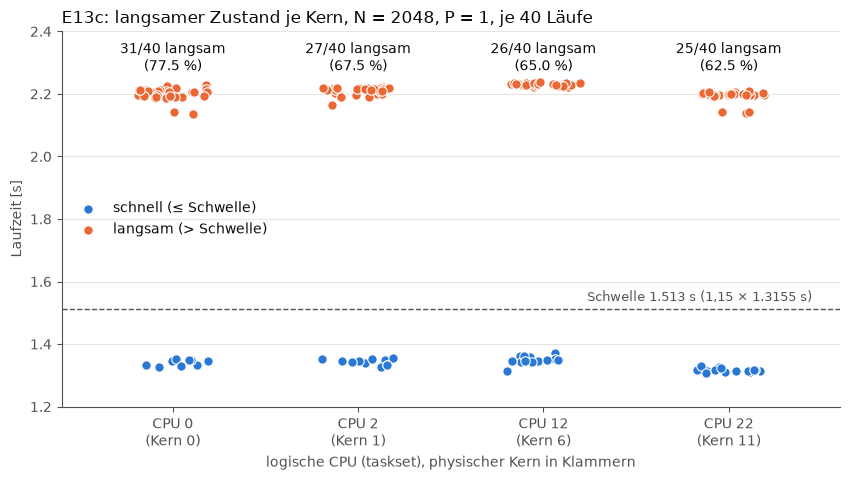

gespeichert: /home/itmvs/waerme/results/e13c_kern_2026-11-09.png 81087 Bytes


In [20]:
kerne = [0, 2, 12, 22]
blau, orange = "#2a78d6", "#eb6834"
rng = np.random.default_rng(1)
fig, a = plt.subplots(figsize=(8.6, 4.9))
for i, k in enumerate(kerne):
    z = np.array(k13[k]); x = i + rng.uniform(-0.2, 0.2, len(z))
    sl = z > schwelle
    a.scatter(x[~sl], z[~sl], s=46, color=blau, edgecolor="white", linewidth=0.8, zorder=3,
              label="schnell (≤ Schwelle)" if i == 0 else None)
    a.scatter(x[sl], z[sl], s=46, color=orange, edgecolor="white", linewidth=0.8, zorder=3,
              label="langsam (> Schwelle)" if i == 0 else None)
    n, lang, _ = e13c[k]
    a.text(i, 2.37, f"{lang}/{n} langsam\n({100 * lang / n:.1f} %)", ha="center", va="top", color=tinte, fontsize=10)
a.axhline(schwelle, color=grau, lw=1, ls="--", zorder=2)
a.text(len(kerne) - 0.55, schwelle + 0.015, f"Schwelle {schwelle:.3f} s (1,15 × {ref:.4f} s)", ha="right", va="bottom", color=grau, fontsize=9)
a.set_ylim(1.2, 2.4); a.set_xlim(-0.6, len(kerne) - 0.4)
a.set_xticks(range(len(kerne))); a.set_xticklabels([f"CPU {k}\n(Kern {k // 2})" for k in kerne])
a.set_xlabel("logische CPU (taskset), physischer Kern in Klammern", color=grau); a.set_ylabel("Laufzeit [s]", color=grau)
a.set_title("E13c: langsamer Zustand je Kern, N = 2048, P = 1, je 40 Läufe", color=tinte, fontsize=12, loc="left")
a.grid(True, axis="y", color=raster, lw=0.8); a.set_axisbelow(True)
for s in ("top", "right"): a.spines[s].set_visible(False)
for s in ("left", "bottom"): a.spines[s].set_color(grau)
a.tick_params(colors=grau); a.legend(frameon=False, labelcolor=tinte, loc="center left")
fig.tight_layout()
datei = R + "e13c_kern_2026-11-09.png"
fig.savefig(datei, dpi=150, facecolor="white")
plt.show()
print("gespeichert:", datei, os.path.getsize(datei), "Bytes")

In [21]:
f13d = R + "e13d_bloecke_2026-11-09.csv"
z13d = list(csv.reader(open(f13d)))
print("Datei:", f13d)
print("Kopfzeile:", ",".join(z13d[0]))
print("Spalten in Kopfzeile:", len(z13d[0]))
print("Zeilen:", len(z13d), "(erwartet 61)")
print("Spalten je Datenzeile (verschieden):", sorted(set(len(r) for r in z13d[1:])))
print("Beispiel (erste 8 Felder):", z13d[1][:8])
print("verschiedene Summen:", len(set(r[z13d[0].index("summe")] for r in z13d[1:])) if "summe" in z13d[0] else "Spalte summe fehlt")

Datei: /home/itmvs/waerme/results/e13d_bloecke_2026-11-09.csv
Kopfzeile: datum,P,N,schritte,zeit_s,komm_max_s,summe,b1,b2,b3,b4,b5,b6,b7,b8,b9,b10,b11,b12,b13,b14,b15,b16,b17,b18,b19,b20
Spalten in Kopfzeile: 27
Zeilen: 61 (erwartet 61)
Spalten je Datenzeile (verschieden): [27]
Beispiel (erste 8 Felder): ['2026-11-09_11:56:53', '1', '2048', '200', '2.173466', '0.003619', '1.3566003078e+06', '0.11123']
verschiedene Summen: 1


In [22]:
b = np.array([[float(x) for x in r[7:27]] for r in z13d[1:]])
zt = np.array([float(r[4]) for r in z13d[1:]])
ref = float(np.median(np.sort(zt)[:6])); schw = 1.15 * ref
lang = zt > schw
print(f"Läufe: {len(zt)}, Blöcke je Lauf: {b.shape[1]}")
print(f"Referenz (Median der 6 schnellsten): {ref:.4f} s, Schwelle: {schw:.4f} s")
print(f"schnell {(~lang).sum()}, langsam {lang.sum()} ({100 * lang.mean():.1f} %)")
med = {}
for name, m in (("schnell", ~lang), ("langsam", lang)):
    bb = b[m]
    mm = bb.max(axis=1) / bb.min(axis=1)
    med[name] = float(np.median(bb))
    print(f"{name}: {m.sum()} Läufe, Median aller Blöcke {np.median(bb):.5f} s, "
          f"Median der Lauf-Mediane {np.median(np.median(bb, axis=1)):.5f} s, "
          f"max/min je Lauf: Median {np.median(mm):.3f}, größter {mm.max():.3f}")
print(f"Faktor langsam/schnell (Median aller Blöcke): {med['langsam'] / med['schnell']:.2f}")
sprung = np.max(np.abs(b[:, 1:] / b[:, :-1] - 1), axis=1)
print(f"größter Sprung zwischen aufeinanderfolgenden Blöcken: {100 * sprung.max():.1f} %; Läufe mit Sprung > 20 %: {(sprung > 0.2).sum()} von {len(zt)}")
rel = np.max(np.abs(b / np.median(b, axis=1, keepdims=True) - 1), axis=1)
print(f"Läufe mit einem Block > 20 % neben dem Lauf-Median: {(rel > 0.2).sum()} von {len(zt)}")
abw = np.abs(b.sum(axis=1) - zt) / zt
print(f"Summe der 20 Blöcke gegen zeit_s: größte Abweichung {100 * abw.max():.2f} %")

Läufe: 60, Blöcke je Lauf: 20
Referenz (Median der 6 schnellsten): 1.3488 s, Schwelle: 1.5511 s
schnell 11, langsam 49 (81.7 %)
schnell: 11 Läufe, Median aller Blöcke 0.06751 s, Median der Lauf-Mediane 0.06746 s, max/min je Lauf: Median 1.025, größter 1.043
langsam: 49 Läufe, Median aller Blöcke 0.11156 s, Median der Lauf-Mediane 0.11157 s, max/min je Lauf: Median 1.021, größter 1.135
Faktor langsam/schnell (Median aller Blöcke): 1.65
größter Sprung zwischen aufeinanderfolgenden Blöcken: 8.8 %; Läufe mit Sprung > 20 %: 0 von 60
Läufe mit einem Block > 20 % neben dem Lauf-Median: 0 von 60
Summe der 20 Blöcke gegen zeit_s: größte Abweichung 0.00 %


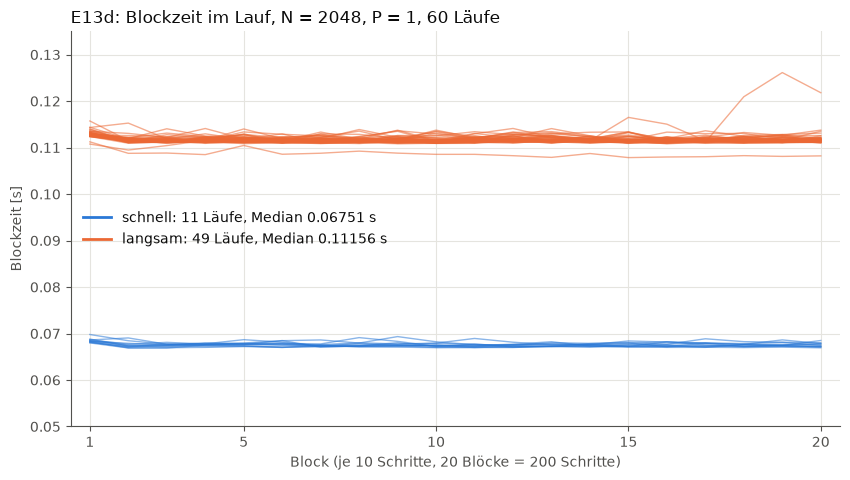

gespeichert: /home/itmvs/waerme/results/e13d_bloecke_2026-11-09.png 95617 Bytes


In [23]:
blau, orange = "#2a78d6", "#eb6834"
x = np.arange(1, 21)
fig, a = plt.subplots(figsize=(8.6, 4.9))
for farbe, m, name in ((blau, ~lang, f"schnell: {(~lang).sum()} Läufe, Median {med['schnell']:.5f} s"),
                       (orange, lang, f"langsam: {lang.sum()} Läufe, Median {med['langsam']:.5f} s")):
    for j, zeile in enumerate(b[m]):
        a.plot(x, zeile, color=farbe, lw=1.0, alpha=0.55, label=name if j == 0 else None, zorder=2)
a.set_xlim(0.5, 20.5); a.set_ylim(0.05, 0.135)
a.set_xticks([1, 5, 10, 15, 20])
a.set_xlabel("Block (je 10 Schritte, 20 Blöcke = 200 Schritte)", color=grau); a.set_ylabel("Blockzeit [s]", color=grau)
a.set_title("E13d: Blockzeit im Lauf, N = 2048, P = 1, 60 Läufe", color=tinte, fontsize=12, loc="left")
a.grid(True, color=raster, lw=0.8); a.set_axisbelow(True)
for s in ("top", "right"): a.spines[s].set_visible(False)
for s in ("left", "bottom"): a.spines[s].set_color(grau)
a.tick_params(colors=grau)
leg = a.legend(frameon=False, labelcolor=tinte, loc="center left")
for l in leg.get_lines(): l.set_alpha(1); l.set_linewidth(2)
fig.tight_layout()
datei = R + "e13d_bloecke_2026-11-09.png"
fig.savefig(datei, dpi=150, facecolor="white")
plt.show()
print("gespeichert:", datei, os.path.getsize(datei), "Bytes")